In [1]:
%matplotlib inline

from pathlib import Path
import sys

# Locate the repository from either the root or notebooks folder.
project_root = Path.cwd()
if not (project_root / "uuv_mission").is_dir():
    project_root = project_root.parent

sys.path.insert(0, str(project_root))

import numpy as np
from uuv_mission.dynamic import Submarine, Mission, ClosedLoop
from uuv_mission.control import PDController

In [2]:
mission = Mission.from_csv(
    str(project_root / "data" / "mission.csv")
)

submarine = Submarine()
controller = PDController(kp=0.15, kd=0.6)
closed_loop = ClosedLoop(submarine, controller)

print(f"Mission loaded: {len(mission.reference)} steps.")

Mission loaded: 100 steps.


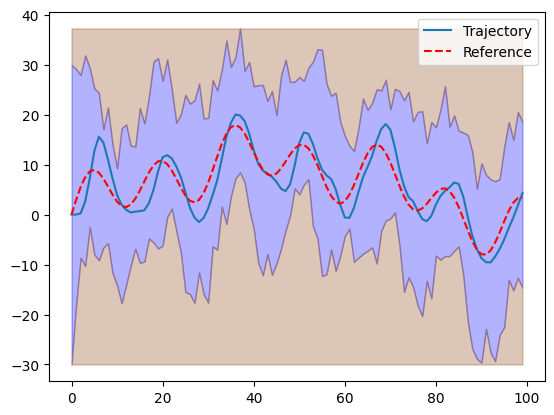

In [3]:
# Make the random disturbances repeatable.
np.random.seed(42)

trajectory = closed_loop.simulate_with_random_disturbances(mission)
trajectory.plot_completed_mission(mission)